# 05 · Emerging technologies and institutions

Sub-area (domain cluster) counts per year, the emerging list ranked by recent growth, the
back-test of the detection rule, and institution profiles, similarity and network.
Produced by `python -m src.pipeline.trends` and `python -m src.pipeline.institutions`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
FIG = Path("reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
out = Path("data/outputs")
trends = pd.read_parquet(out / "trends.parquet")
emerging = pd.read_parquet(out / "emerging.parquet")
domain_trends = pd.read_parquet(out / "domain_trends.parquet")
bt = json.loads(Path("reports/trend_backtest.json").read_text())
inst = pd.read_parquet(out / "institutions.parquet")
net = json.loads((out / "institution_network.json").read_text())

## Domain volume over time (patents and papers)

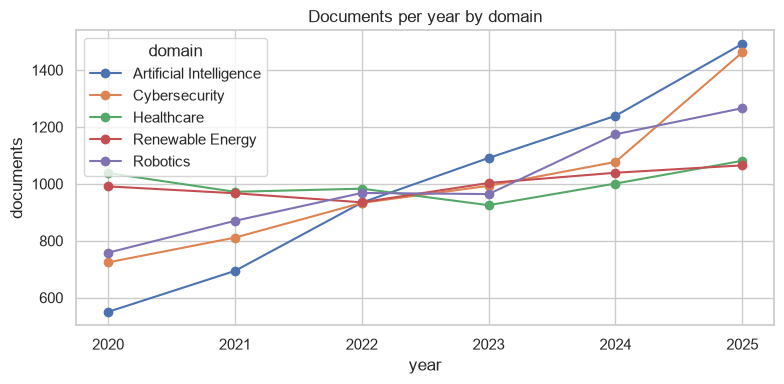

In [2]:
pivot = domain_trends.groupby(["year", "domain"])["count"].sum().unstack()
ax = pivot.plot(marker="o", figsize=(8, 4)); ax.set_ylabel("documents"); ax.set_title("Documents per year by domain")
plt.tight_layout(); plt.savefig(FIG / "domain_trends.png", dpi=150); plt.show()

## Emerging sub-areas
Ranked by recent growth, (n2024 + n2025 + 1) / (n2022 + n2023 + 1) − 1, among sub-areas with at
least 40 documents.

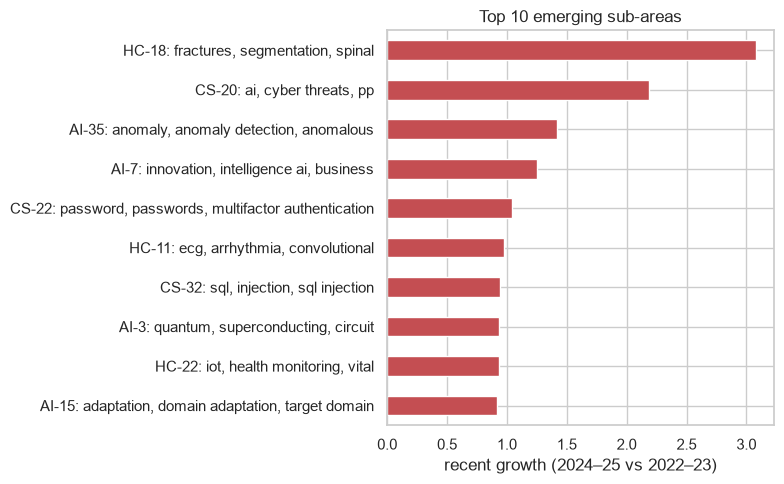

,cluster_id,domain,size,recent_growth,cagr
0,HC-18,Healthcare,82,3.0769,0.3356
1,CS-20,Cybersecurity,131,2.1852,0.3852
2,AI-35,Artificial Intelligence,44,1.4167,0.4465
3,AI-7,Artificial Intelligence,175,1.2500,0.4541
4,CS-22,Cybersecurity,98,1.0435,0.1636
5,HC-11,Healthcare,161,0.9787,0.3643
6,CS-32,Cybersecurity,75,0.9412,0.0313
7,AI-3,Artificial Intelligence,239,0.9355,0.2423
8,HC-22,Healthcare,132,0.9333,0.0810
9,AI-15,Artificial Intelligence,124,0.9167,0.3026


In [3]:
top = emerging.head(10).copy()
top["label"] = top["cluster_id"] + ": " + top["keywords"].map(lambda k: ", ".join(list(k)[:3]))
ax = top.set_index("label")["recent_growth"].sort_values().plot.barh(figsize=(8, 5), color="#C44E52")
ax.set_xlabel("recent growth (2024–25 vs 2022–23)"); ax.set_ylabel(""); ax.set_title("Top 10 emerging sub-areas")
plt.tight_layout(); plt.savefig(FIG / "emerging_top10.png", dpi=150); plt.show()
top[["cluster_id", "domain", "size", "recent_growth", "cagr"]]

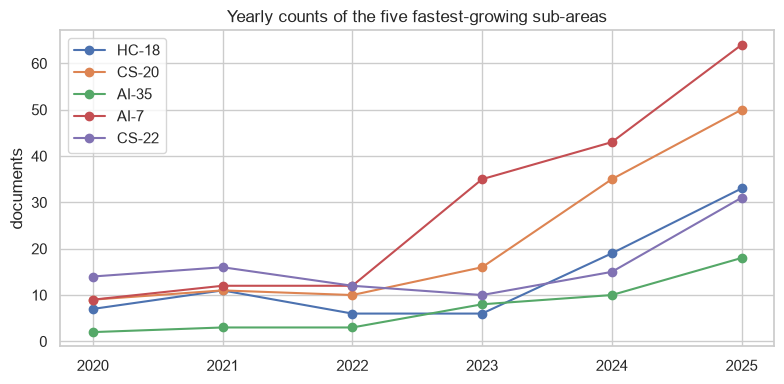

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for cid in top["cluster_id"].head(5):
    s = trends[trends["cluster_id"] == cid].set_index("year")["count"]
    ax.plot(s.index, s.values, marker="o", label=cid)
ax.set_ylabel("documents"); ax.set_title("Yearly counts of the five fastest-growing sub-areas"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "emerging_series.png", dpi=150); plt.show()

## Back-test of the detection rule
Clusters are flagged using 2020–2023 only, then checked against 2024–2025. A hit rate close to
the base rate means the two-year-window rule does not predict later growth better than chance:
most sub-areas grew over this period, and clusters of 40–200 documents give noisy yearly counts.

In [5]:
pd.Series({k: bt[k] for k in ("eligible_clusters", "flagged", "hit_rate", "base_rate_not_flagged",
                               "mean_later_growth_flagged", "mean_later_growth_not_flagged")})

eligible_clusters                157.0000
flagged                           20.0000
hit_rate                           0.7000
base_rate_not_flagged              0.6934
mean_later_growth_flagged          0.2198
mean_later_growth_not_flagged      0.2518
dtype: float64

## Institutions
Profiles cover institutions with at least 10 documents. Similarity is the cosine between their
mean embeddings.

In [6]:
print(f"{len(inst)} institutions profiled; {len(net['edges'])} network edges (rule: {net['rule']})")
inst.sort_values("documents", ascending=False).head(10)[["name", "country", "documents", "patents", "papers", "top_domain"]]

605 institutions profiled; 2210 network edges (rule: similarity >= 0.8028 (99th percentile) or >= 3 shared sub-areas; max 8 edges per node)


,name,country,documents,patents,papers,top_domain
238,Electronics and Telecommunications Research In...,KR,408,402,6,Cybersecurity
111,University California,US,343,343,0,Healthcare
343,Massachusetts Institute of Technology,US,274,253,21,Artificial Intelligence
15,Korea Advanced Institute of Science and Techno...,KR,241,211,30,Artificial Intelligence
327,Industrial Technology Research Institute,TW,238,238,0,Robotics
569,Tsinghua University,CN,226,183,43,Renewable Energy
601,Zhejiang University,CN,204,135,69,Artificial Intelligence
458,Seoul National University,KR,184,142,42,Artificial Intelligence
541,Stanford University,US,182,143,39,Healthcare
432,University of Michigan,US,178,139,39,Healthcare


In [7]:
sim = pd.read_parquet(out / "institution_similarity.parquet")
names = inst.set_index("institution")["name"]
example = inst.sort_values("documents", ascending=False).iloc[0]["institution"]
print("Most similar to", names[example])
sim[sim["institution"] == example].assign(name=lambda t: t["similar_institution"].map(names))[["name", "similarity"]]

Most similar to Electronics and Telecommunications Research Institute


,name,similarity
2380,Ajou University,0.9215
2381,Korea University,0.9169
2382,Korea Advanced Institute of Science and Techno...,0.9167
2383,University Yonsei Iacf,0.9075
2384,Institute Information Industrial,0.9044
2385,Postech Research & Business Dev Foundation,0.8962
2386,University Industry Cooperation Group Kyung He...,0.8835
2387,Seoul National University,0.8787
2388,Research & Business Foundation Sungkyunkwan Un...,0.8745
2389,Stanford Research Institute Int,0.8714


## Institution network
Nodes coloured by their main domain; the largest connected component is drawn.

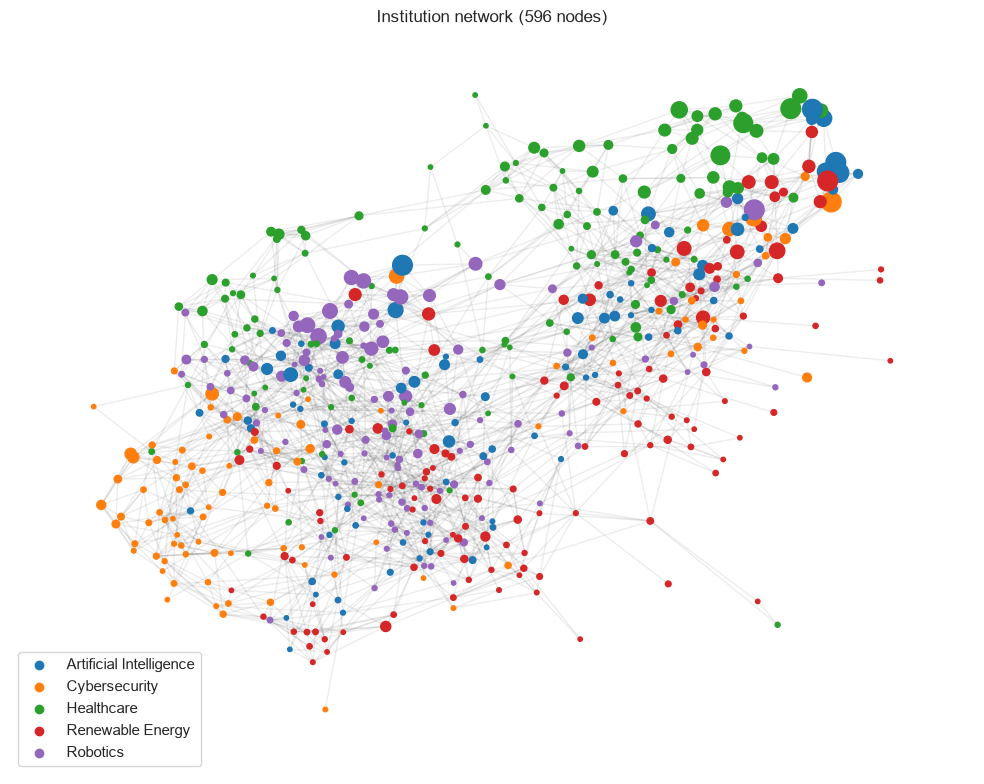

Texas A & M University Sys                            8
Texas A&M University                                  8
RWTH Aachen University                                8
Aalborg University                                    8
Aarhus University                                     8
Prince Sattam Bin Abdulaziz University                8
King Abdulaziz University                             8
King Abdullah University of Science and Technology    8
dtype: int64

In [8]:
G = nx.Graph()
for n in net["nodes"]:
    G.add_node(n["id"], **n)
for e in net["edges"]:
    G.add_edge(e["source"], e["target"], weight=e["similarity"])
core = G.subgraph(max(nx.connected_components(G), key=len))
palette = dict(zip(sorted({d["top_domain"] for _, d in core.nodes(data=True)}), sns.color_palette("tab10")))
pos = nx.spring_layout(core, seed=42, k=0.15)
fig, ax = plt.subplots(figsize=(10, 8))
nx.draw_networkx_edges(core, pos, alpha=0.08, ax=ax)
nx.draw_networkx_nodes(core, pos, node_size=[min(200, d["documents"]) for _, d in core.nodes(data=True)],
                       node_color=[palette[d["top_domain"]] for _, d in core.nodes(data=True)], ax=ax)
for dom, col in palette.items():
    ax.scatter([], [], color=col, label=dom)
ax.legend(loc="lower left"); ax.set_axis_off(); ax.set_title(f"Institution network ({core.number_of_nodes()} nodes)")
plt.tight_layout(); plt.savefig(FIG / "institution_network.png", dpi=150); plt.show()
pd.Series(dict(nx.degree(core))).nlargest(8).rename(index=names)